# 05 Who moves first: Part A (build years only)
Build years = 1999-01-04 to 2020-12-31. **Nothing dated 2021 or later is loaded or computed here** (the file is filtered while reading).

Question: does one market's return today help predict another market's return in the next period? **"A leads B"** = correlation of A's return in period t with B's return in period t+1, using only periods where both exist. Every ordered pair is done separately (A leads B and B leads A). Self-pairs (A leads A, i.e. autocorrelation: does a market's move today predict its own move tomorrow) are reported separately and do not count toward M1-M3.

- **Returns:** from adjusted closes (dividends included). **Daily:** 23 symbols, **BTC-USD excluded** (its daily close is 00:00 UTC, about 4 hours after US stocks close, which would fake a lead). **Weekly:** last trading day of each week (Monday-Sunday weeks) to the next, all 24 symbols including BTC-USD.
- **Noise band** for each pair: +/- 1.96 / sqrt(n), n = number of periods used. A correlation outside it is "unlikely to be pure chance" for that one pair; with hundreds of pairs, about 5% fall outside by chance alone.
- **Two views:** *plain* returns (the main test, judged against M1-M3) and *market-removed* returns (as in notebook 01: each symbol's return minus the part explained by the equal-weight sector average, fitted within each calendar year; information only). Weekly market-removed fits need at least 26 weekly returns per symbol-year (the daily fit needs 120 days, as in notebook 01).
- **Year by year:** a pair-year belongs to the year of the follower's period (t+1); daily needs 120+ pairs of days in a year, weekly 26+. **Steady lead** = outside the band over the full period AND same sign as the full period in at least 75% of the years the pair exists.
- **Cost reminder:** a lag correlation of a few hundredths is unlikely to survive the 0.10%-per-trade cost.
- **Thin-trading warning:** in early years (1999-2001) a thinly traded fund's price can catch up a day late, which looks like "following". The year-by-year tables below are checked for this.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
if not (ROOT / "config.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import config
from rotation.data import load_prices, wide
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 300)
R = config.RESULTS_DIR; R.mkdir(exist_ok=True)
SECT = config.SECTORS
ORDER_ALL = config.SECTORS + config.INDUSTRIES + ["SPY", "QQQ", "IWM", "GLD", "TLT", "USO", "UUP", "EEM", "BTC-USD"]
ORDER_D = [s for s in ORDER_ALL if s != "BTC-USD"]          # daily: no BTC-USD
MIN_YEAR = {"daily": 120, "weekly": 26}
MIN_RESID = {"daily": 120, "weekly": 26}
Z95 = 1.96

## 1. Load build years only; daily and weekly returns

In [2]:
df = load_prices(fields=["adj_close"], end=config.BUILD_END)
assert df.date.max() <= pd.Timestamp(config.BUILD_END)
P = wide(df, "adj_close")[ORDER_ALL]
# daily (23 symbols, no BTC-USD)
rd = P[ORDER_D].pct_change(fill_method=None).iloc[1:]
# weekly: last trading day of each Monday-Sunday week to the next (24 symbols)
idx = P.index.to_series()
last_of_week = idx.groupby(idx.dt.to_period("W")).max()
Pw = P.loc[last_of_week.values]
rw = Pw.pct_change(fill_method=None).iloc[1:]
RET = {"daily": rd, "weekly": rw}
print("daily:", rd.index.min().date(), "to", rd.index.max().date(), "|", len(rd), "days |", rd.shape[1], "symbols")
print("weekly:", rw.index.min().date(), "to", rw.index.max().date(), "|", len(rw), "weeks |", rw.shape[1], "symbols")

daily: 1999-01-05 to 2020-12-31 | 5535 days | 23 symbols
weekly: 1999-01-15 to 2020-12-31 | 1147 weeks | 24 symbols


## 2. Market-removed returns (information-only view)
Same method as notebook 01: market = equal-weight average of the sector funds that exist in that period; per symbol and calendar year, regress the return on the market and keep the leftover.

In [3]:
def resid(ret, market, min_obs):
    out = pd.DataFrame(np.nan, index=ret.index, columns=ret.columns)
    for s in ret.columns:
        for y, g in ret[s].groupby(ret.index.year):
            d = pd.concat([g, market.loc[g.index]], axis=1, keys=["r", "m"]).dropna()
            if len(d) < min_obs:
                continue
            b, a = np.polyfit(d["m"], d["r"], 1)
            out.loc[d.index, s] = d["r"] - (a + b * d["m"])
    return out
RES = {f: resid(RET[f], RET[f][SECT].mean(axis=1, skipna=True), MIN_RESID[f]) for f in RET}
VIEWS = {"plain": RET, "market-removed": RES}
print({f: int(RES[f].notna().sum().min()) for f in RES}, "(fewest leftover periods for any symbol)")

{'daily': 639, 'weekly': 132} (fewest leftover periods for any symbol)


## 3. Lag-1 correlation machinery
`lag_corr(R, rows)` returns, for every ordered pair (leader i, follower j), the correlation of i's return in period t with j's return in period t+1 and the number of periods used. `rows` optionally limits the pairs to those whose follower period falls in a given set (used for years).

In [4]:
def lag_corr(Rt, row_mask=None):
    Z = Rt.values
    X, Y = Z[:-1], Z[1:]
    keep = np.ones(len(X), bool) if row_mask is None else row_mask[1:]      # row_mask is indexed by follower period
    k = Z.shape[1]
    corr = np.full((k, k), np.nan); nn = np.zeros((k, k), int)
    for i in range(k):
        xi = X[:, i]
        for j in range(k):
            m = keep & ~(np.isnan(xi) | np.isnan(Y[:, j]))
            n_ = int(m.sum()); nn[i, j] = n_
            if n_ >= 3:
                corr[i, j] = np.corrcoef(xi[m], Y[m, j])[0, 1]
    return pd.DataFrame(corr, index=Rt.columns, columns=Rt.columns), pd.DataFrame(nn, index=Rt.columns, columns=Rt.columns)

def same_day_corr(Rt, a, b):
    d = Rt[[a, b]].dropna()
    return d[a].corr(d[b]) if len(d) >= 3 else np.nan

def pair_table(Rt):
    c, n = lag_corr(Rt)
    rows = []
    for a in Rt.columns:
        for b in Rt.columns:
            if a == b or np.isnan(c.loc[a, b]):
                continue
            nn = n.loc[a, b]; band = Z95 / np.sqrt(nn)
            rows.append(dict(leader=a, follower=b, n=nn, lag1_corr=c.loc[a, b], band=band, outside=abs(c.loc[a, b]) > band))
    return pd.DataFrame(rows)

def year_table(Rt, freq):
    out = []
    for y in sorted(set(Rt.index[1:].year)):
        mask = (Rt.index.year == y)
        c, n = lag_corr(Rt, mask)
        for a in Rt.columns:
            for b in Rt.columns:
                if n.loc[a, b] >= MIN_YEAR[freq] and not np.isnan(c.loc[a, b]):
                    out.append(dict(year=y, leader=a, follower=b, lag1_corr=c.loc[a, b], n=int(n.loc[a, b])))
    return pd.DataFrame(out)

full, yearly = {}, {}
for view, D in VIEWS.items():
    for f in ("daily", "weekly"):
        full[(view, f)] = pair_table(D[f])
        yearly[(view, f)] = year_table(D[f], f)
        t = full[(view, f)]
        print(f"{view:15s} {f:7s}: {len(t):4d} ordered pairs | outside band {t.outside.sum():3d} ({t.outside.mean()*100:.1f}%) | max |corr| {t.lag1_corr.abs().max():.3f} | pair-year rows {len(yearly[(view, f)])}")

plain           daily  :  506 ordered pairs | outside band 415 (82.0%) | max |corr| 0.291 | pair-year rows 8258


plain           weekly :  552 ordered pairs | outside band 155 (28.1%) | max |corr| 0.282 | pair-year rows 8532


market-removed  daily  :  506 ordered pairs | outside band 118 (23.3%) | max |corr| 0.114 | pair-year rows 8258


market-removed  weekly :  552 ordered pairs | outside band  59 (10.7%) | max |corr| 0.163 | pair-year rows 8532


## 4. Result 1 (plain view): full-period lag-1 correlation for every ordered pair
Table of every pair saved; share of pairs outside the 95% noise band; the 15 largest by size (with the same-day correlation for scale).

In [5]:
summary_rows = []
for f in ("daily", "weekly"):
    t = full[("plain", f)].copy()
    t["same_day_corr"] = [same_day_corr(RET[f], a, b) for a, b in zip(t.leader, t.follower)]
    t.round(5).to_csv(R / f"05_{f}_lag1_plain.csv", index=False)
    top = t.reindex(t.lag1_corr.abs().sort_values(ascending=False).index).head(15)
    top.round(4).to_csv(R / f"05_top15_{f}_plain.csv", index=False)
    summary_rows.append(dict(freq=f, view="plain", ordered_pairs=len(t), outside_band=int(t.outside.sum()), share_outside_pct=t.outside.mean() * 100,
                             share_positive_pct=(t.lag1_corr > 0).mean() * 100, max_abs_corr=t.lag1_corr.abs().max(),
                             median_abs_corr=t.lag1_corr.abs().median(), pairs_abs_corr_above_0_10=int((t.lag1_corr.abs() > 0.10).sum())))
    print(f"=== {f}: share outside the band {t.outside.mean()*100:.1f}% of {len(t)} pairs (chance alone would give about 5%) ===")
    print("largest 15 by size:"); print(top[["leader", "follower", "n", "lag1_corr", "band", "same_day_corr", "outside"]].round(3).to_string(index=False)); print()
pd.DataFrame(summary_rows).round(3)

=== daily: share outside the band 82.0% of 506 pairs (chance alone would give about 5%) ===
largest 15 by size:
leader follower   n  lag1_corr  band  same_day_corr  outside
   XLC      UUP 638     -0.291 0.078          0.107     True
   XLC      SMH 638     -0.278 0.078          0.800     True
   XLC      XLK 638     -0.275 0.078          0.903     True
   XLF      XLC 639     -0.261 0.078          0.728     True
   SPY      XLC 639     -0.260 0.078          0.903     True
   XLC      EEM 638     -0.260 0.078          0.760     True
   XLC      QQQ 638     -0.256 0.078          0.933     True
   XLK      XLC 639     -0.256 0.078          0.903     True
   XLV      XLC 639     -0.250 0.078          0.779     True
   XLP      XLC 639     -0.248 0.078          0.692     True
   XLC      XLP 638     -0.247 0.078          0.692     True
   QQQ      XLC 639     -0.242 0.078          0.933     True
   XLC      SPY 638     -0.239 0.078          0.903     True
   EEM      XLC 639     -0.226 0.0

=== weekly: share outside the band 28.1% of 552 pairs (chance alone would give about 5%) ===
largest 15 by size:
 leader follower   n  lag1_corr  band  same_day_corr  outside
   XLRE      XLU 272     -0.282 0.119          0.845     True
BTC-USD      XLC 132      0.224 0.171          0.165     True
   XLRE      UUP 272      0.213 0.119         -0.311     True
   XLRE      IWM 272     -0.205 0.119          0.701     True
    XLC      GLD 131     -0.201 0.171          0.250     True
   XLRE      XLB 272     -0.200 0.119          0.679     True
   XLRE      USO 272      0.191 0.119          0.225     True
   XLRE      ITA 272     -0.190 0.119          0.715     True
    XLC      USO 131      0.186 0.171          0.356     True
   XLRE      XLI 272     -0.183 0.119          0.705     True
   XLRE      XLF 272     -0.175 0.119          0.668     True
    XLC      UUP 131      0.174 0.171         -0.344     True
BTC-USD      XLF 327      0.174 0.108          0.110     True
   XLRE      GLD 27

,freq,view,ordered_pairs,outside_band,share_outside_pct,share_positive_pct,max_abs_corr,median_abs_corr,pairs_abs_corr_above_0_10
0,daily,plain,506,415,82.016,14.032,0.291,0.060,108
1,weekly,plain,552,155,28.080,27.536,0.282,0.048,67


## 5. Result 4: self-pairs (autocorrelation), full period and by year

In [6]:
auto_rows = []
for f in ("daily", "weekly"):
    for view, D in VIEWS.items():
        Rt = D[f]; c, n = lag_corr(Rt)
        for s in Rt.columns:
            nn = n.loc[s, s]
            auto_rows.append(dict(freq=f, view=view, symbol=s, period="full", n=nn, lag1_autocorr=c.loc[s, s], band=Z95 / np.sqrt(nn), outside=abs(c.loc[s, s]) > Z95 / np.sqrt(nn)))
        for y in sorted(set(Rt.index[1:].year)):
            c, n = lag_corr(Rt, Rt.index.year == y)
            for s in Rt.columns:
                if n.loc[s, s] >= MIN_YEAR[f]:
                    auto_rows.append(dict(freq=f, view=view, symbol=s, period=str(y), n=int(n.loc[s, s]), lag1_autocorr=c.loc[s, s], band=Z95 / np.sqrt(n.loc[s, s]), outside=abs(c.loc[s, s]) > Z95 / np.sqrt(n.loc[s, s])))
auto = pd.DataFrame(auto_rows)
auto.round(5).to_csv(R / "05_self_pairs_autocorrelation.csv", index=False)
for f in ("daily", "weekly"):
    a = auto[(auto.freq == f) & (auto.view == "plain") & (auto.period == "full")].set_index("symbol")
    print(f"=== {f} autocorrelation, plain view, full period (symbols outside the band: {int(a.outside.sum())} of {len(a)}) ===")
    print(a[["n", "lag1_autocorr", "band", "outside"]].round(3).to_string()); print()
yrs_auto = auto[(auto.freq == "daily") & (auto.view == "plain") & (auto.period != "full")].pivot(index="symbol", columns="period", values="lag1_autocorr").reindex(ORDER_D)
print("daily autocorrelation by year (plain):"); print(yrs_auto.round(2).to_string())

=== daily autocorrelation, plain view, full period (symbols outside the band: 18 of 23) ===
           n  lag1_autocorr   band  outside
symbol                                     
XLK     5534         -0.074  0.026     True
XLE     5534         -0.060  0.026     True
XLV     5534         -0.041  0.026     True
XLU     5534         -0.091  0.026     True
XLF     5534         -0.105  0.026     True
XLI     5534         -0.041  0.026     True
XLB     5534         -0.041  0.026     True
XLP     5534         -0.087  0.026     True
XLY     5534         -0.028  0.026     True
XLC      638         -0.249  0.078     True
XLRE    1316         -0.118  0.054     True
SMH     5176         -0.042  0.027     True
XBI     3751         -0.022  0.032    False
KRE     3656         -0.101  0.032     True
ITA     3689         -0.015  0.032    False
SPY     5534         -0.092  0.026     True
QQQ     5489         -0.061  0.026     True
IWM     5181         -0.080  0.027     True
GLD     4056         -0.015 

## 6. Result 2 (year by year) and the thin-trading check
Year-by-year lag-1 correlations for every ordered pair are saved. Summary by year: share of ordered pairs outside that year's noise band, and the average lag-1 correlation. Follower profile: for each follower, the average over all other leaders of the yearly lag-1 correlation. A thinly traded fund that catches up late shows a high follower average (many leaders' moves yesterday line up with its move today).

In [7]:
for f in ("daily", "weekly"):
    for view in ("plain", "market-removed"):
        yearly[(view, f)].round(5).to_csv(R / f"05_{f}_lag1_by_year_{'plain' if view == 'plain' else 'market_removed'}.csv", index=False)
sum_year = []
for f in ("daily", "weekly"):
    y = yearly[("plain", f)].copy(); y["band"] = Z95 / np.sqrt(y.n); y["outside"] = y.lag1_corr.abs() > y.band
    y = y[y.leader != y.follower]
    g = y.groupby("year").agg(pairs=("lag1_corr", "size"), share_outside_pct=("outside", lambda s: s.mean() * 100), mean_lag1_corr=("lag1_corr", "mean"),
                              mean_abs_lag1_corr=("lag1_corr", lambda s: s.abs().mean()))
    g.insert(0, "freq", f); sum_year.append(g.reset_index())
sum_year = pd.concat(sum_year); sum_year.round(3).to_csv(R / "05_by_year_summary.csv", index=False)
for f in ("daily", "weekly"):
    print(f"=== {f}, plain view: by year ==="); print(sum_year[sum_year.freq == f].drop(columns="freq").set_index("year").round(2).to_string()); print()
yd = yearly[("plain", "daily")]; yd = yd[yd.leader != yd.follower]
prof = yd.groupby(["year", "follower"]).lag1_corr.mean().unstack().reindex(columns=ORDER_D)
prof.round(4).to_csv(R / "05_follower_profile_daily.csv")
early, late = prof.loc[1999:2003].mean(), prof.loc[2004:].mean()
fp = pd.DataFrame({"early_1999_2003": early, "later_2004_2020": late, "difference": early - late}).sort_values("difference", ascending=False)
print("daily follower profile (average lag-1 correlation over leaders), early vs later years:"); print(fp.round(3).to_string())
print("\nfollower profile by year (rows = years), largest early values:"); print(prof.loc[1999:2004].round(3).to_string())

=== daily, plain view: by year ===
      pairs  share_outside_pct  mean_lag1_corr  mean_abs_lag1_corr
year                                                              
1999    110              20.91           -0.00                0.08
2000    156              15.38            0.03                0.07
2001    156              11.54            0.04                0.07
2002    156               4.49           -0.02                0.06
2003    210              12.38           -0.04                0.07
2004    210               5.71            0.01                0.05
2005    240               7.50           -0.02                0.05
2006    380              18.68            0.01                0.08
2007    420              30.00           -0.08                0.10
2008    420              30.71           -0.06                0.10
2009    420               9.29           -0.03                0.06
2010    420               3.57           -0.02                0.05
2011    420              15

## 7. Result 3: steady leads (candidates for Part B)
Outside the noise band over the full period AND the same sign as the full period in at least 75% of the years the pair exists. Listed with their yearly numbers.

In [8]:
def steady_leads(view, f):
    t = full[(view, f)]; y = yearly[(view, f)]
    out = []
    for _, r in t[t.outside].iterrows():
        yy = y[(y.leader == r.leader) & (y.follower == r.follower)]
        if len(yy) == 0:
            continue
        same = (np.sign(yy.lag1_corr) == np.sign(r.lag1_corr)).mean()
        out.append(dict(leader=r.leader, follower=r.follower, n=r.n, full_corr=r.lag1_corr, band=r.band, years=len(yy), share_years_same_sign=same,
                        median_yearly=yy.lag1_corr.median(), steady=same >= 0.75))
    return pd.DataFrame(out)
SL = {}
for view in ("plain", "market-removed"):
    for f in ("daily", "weekly"):
        s = steady_leads(view, f); SL[(view, f)] = s
        st = s[s.steady] if len(s) else s
        print(f"{view:15s} {f:7s}: outside the band {len(s)} | steady leads {len(st)}")
for f in ("daily", "weekly"):
    s = SL[("plain", f)]; st = s[s.steady].copy()
    if len(st):
        st["same_day_corr"] = [same_day_corr(RET[f], a, b) for a, b in zip(st.leader, st.follower)]
        st["lag_vs_same_day_ratio"] = st.full_corr / st.same_day_corr
        wide_y = yearly[("plain", f)].assign(pair=lambda d: d.leader + " -> " + d.follower)
        yearly_wide = wide_y[wide_y.pair.isin(st.leader + " -> " + st.follower)].pivot(index="pair", columns="year", values="lag1_corr")
        st = st.assign(pair=st.leader + " -> " + st.follower).set_index("pair").join(yearly_wide)
        st.round(4).to_csv(R / f"05_steady_leads_{f}_plain.csv")
        print(f"\n=== STEADY LEADS, {f}, plain view ({len(st)}) ==="); print(st.round(3).to_string())
    else:
        pd.DataFrame(columns=["leader", "follower"]).to_csv(R / f"05_steady_leads_{f}_plain.csv", index=False)
        print(f"\n=== STEADY LEADS, {f}, plain view: none ===")
    print(f"(also outside the band over the full period but not steady: {int((~s.steady).sum())})")

plain           daily  : outside the band 415 | steady leads 115
plain           weekly : outside the band 155 | steady leads 64


market-removed  daily  : outside the band 118 | steady leads 23
market-removed  weekly : outside the band 59 | steady leads 11



=== STEADY LEADS, daily, plain view (115) ===
            leader follower     n  full_corr   band  years  share_years_same_sign  median_yearly  steady  same_day_corr  lag_vs_same_day_ratio   1999   2000   2001   2002   2003   2004   2005   2006   2007   2008   2009   2010   2011   2012   2013   2014   2015   2016   2017   2018   2019   2020
pair                                                                                                                                                                                                                                                                                                    
XLK -> XLP     XLK      XLP  5534     -0.112  0.026     22                  0.864         -0.082    True          0.488                 -0.230  0.003 -0.149 -0.068 -0.061 -0.214 -0.038 -0.057 -0.086 -0.090 -0.149 -0.039 -0.077 -0.135 -0.010 -0.100 -0.078  0.028 -0.108 -0.130  0.078 -0.101 -0.337
XLK -> XLC     XLK      XLC   639     -0.256  0.078      3    

## 8. Results 5 and 6: same-day correlation for scale, and the market-removed view (information only)

In [9]:
for view in ("market-removed",):
    rows = []
    for f in ("daily", "weekly"):
        t = full[(view, f)]; st = SL[(view, f)]
        t.round(5).to_csv(R / f"05_{f}_lag1_market_removed.csv", index=False)
        top = t.reindex(t.lag1_corr.abs().sort_values(ascending=False).index).head(15); top.round(4).to_csv(R / f"05_top15_{f}_market_removed.csv", index=False)
        rows.append(dict(freq=f, view=view, ordered_pairs=len(t), outside_band=int(t.outside.sum()), share_outside_pct=t.outside.mean() * 100,
                         max_abs_corr=t.lag1_corr.abs().max(), pairs_abs_corr_above_0_10=int((t.lag1_corr.abs() > 0.10).sum()),
                         steady_leads=int(st.steady.sum()) if len(st) else 0))
        print(f"=== {f}, market-removed view: share outside the band {t.outside.mean()*100:.1f}%, largest 15 ==="); print(top[["leader", "follower", "n", "lag1_corr", "band", "outside"]].round(3).to_string(index=False)); print()
        if len(st) and st.steady.any():
            s2 = st[st.steady].copy(); s2.round(4).to_csv(R / f"05_steady_leads_{f}_market_removed.csv", index=False)
            print(f"steady leads ({f}, market-removed):"); print(s2.round(3).to_string(index=False))
        else:
            pd.DataFrame(columns=["leader", "follower"]).to_csv(R / f"05_steady_leads_{f}_market_removed.csv", index=False); print(f"steady leads ({f}, market-removed): none")
        print()
shares = pd.concat([pd.DataFrame(summary_rows), pd.DataFrame(rows)], ignore_index=True)
shares["steady_leads"] = shares.apply(lambda r: (int(SL[(r.view, r.freq)].steady.sum()) if len(SL[(r.view, r.freq)]) else 0), axis=1)
shares.round(3).to_csv(R / "05_summary_shares.csv", index=False)
shares.round(3)

=== daily, market-removed view: share outside the band 23.3%, largest 15 ===
leader follower    n  lag1_corr  band  outside
   SPY      IWM 5182     -0.114 0.027     True
   SPY      XLV 5534      0.107 0.026     True
   SPY      SMH 5177     -0.094 0.027     True
   SPY      EEM 4461     -0.094 0.029     True
   SPY      QQQ 5490     -0.092 0.026     True
   QQQ      XLP 5489     -0.091 0.026     True
   XLC      XLE  638      0.090 0.078     True
   QQQ      XLV 5489      0.087 0.026     True
   XLC      XLU  638     -0.076 0.078    False
   XLC      XLP  638     -0.073 0.078    False
   TLT      XLU 4531      0.072 0.029     True
   QQQ      XLK 5489      0.071 0.026     True
   XLC      ITA  638     -0.068 0.078    False
   TLT     XLRE 1259      0.067 0.055     True
   XLC      USO  638      0.066 0.078    False

steady leads (daily, market-removed):
leader follower    n  full_corr  band  years  share_years_same_sign  median_yearly  steady
   XLV      QQQ 5490     -0.029 0.026    

,freq,view,ordered_pairs,outside_band,share_outside_pct,share_positive_pct,max_abs_corr,median_abs_corr,pairs_abs_corr_above_0_10,steady_leads
0,daily,plain,506,415,82.016,14.032,0.291,0.060,108,115
1,weekly,plain,552,155,28.080,27.536,0.282,0.048,67,64
2,daily,market-removed,506,118,23.320,NaN,0.114,NaN,2,23
3,weekly,market-removed,552,59,10.688,NaN,0.163,NaN,43,11


## 9. Result 7: heatmap of daily lag-1 correlations (rows = leader, columns = follower; plain view)

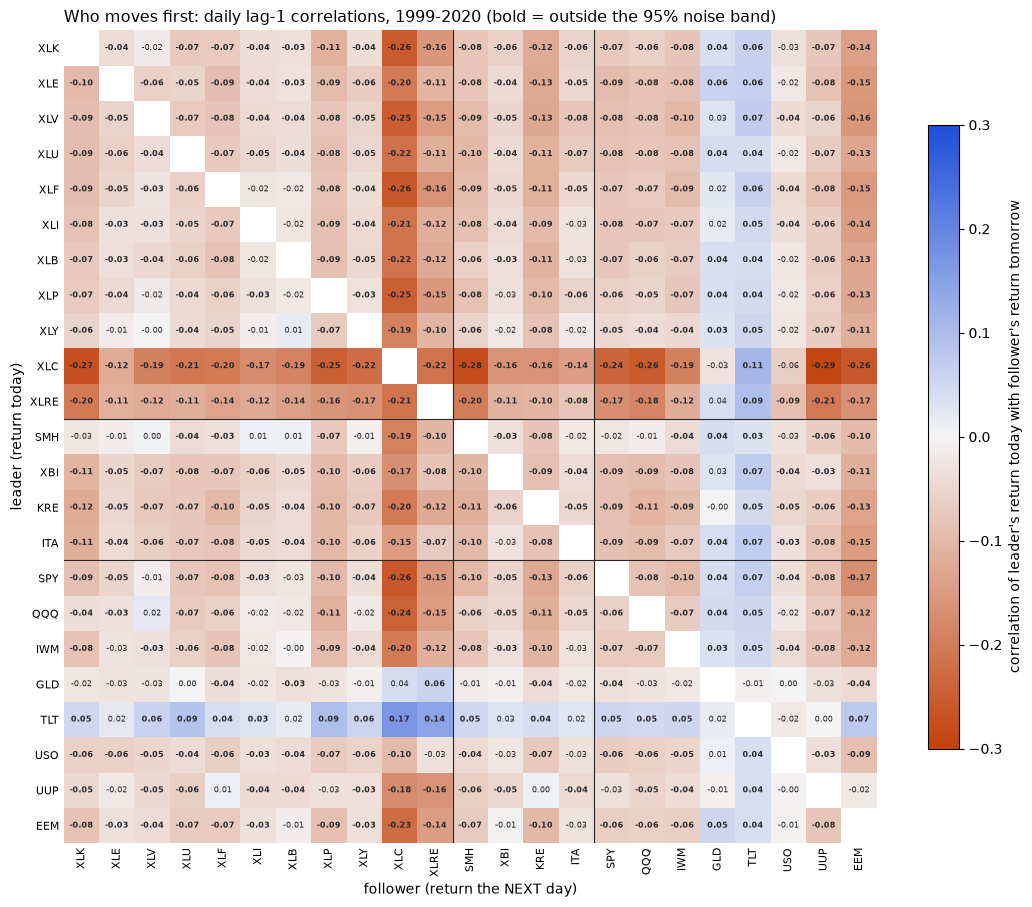

colour scale +/- 0.3


In [10]:
cD, nD = lag_corr(RET["daily"])
mat = cD.reindex(index=ORDER_D, columns=ORDER_D).copy()
for s in ORDER_D: mat.loc[s, s] = np.nan                     # self-pairs are in their own table
lim = float(np.ceil(np.nanmax(np.abs(mat.values)) * 100) / 100)
cmap = LinearSegmentedColormap.from_list("div", ["#c2410c", "#f4f4f5", "#1d4ed8"])
fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(mat.values, cmap=cmap, vmin=-lim, vmax=lim)
ax.set_xticks(range(len(ORDER_D))); ax.set_xticklabels(ORDER_D, rotation=90, fontsize=8); ax.set_yticks(range(len(ORDER_D))); ax.set_yticklabels(ORDER_D, fontsize=8)
for i in range(len(ORDER_D)):
    for j in range(len(ORDER_D)):
        v = mat.values[i, j]
        if pd.notna(v):
            n_ = nD.loc[ORDER_D[i], ORDER_D[j]]; out = abs(v) > Z95 / np.sqrt(n_)
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=5.5, color="#27272a", fontweight="bold" if out else "normal")
for k in (10.5, 14.5):
    ax.axhline(k, color="#27272a", lw=0.8); ax.axvline(k, color="#27272a", lw=0.8)
for sp in ax.spines.values(): sp.set_visible(False)
ax.tick_params(length=0); ax.set_xlabel("follower (return the NEXT day)"); ax.set_ylabel("leader (return today)")
ax.set_title("Who moves first: daily lag-1 correlations, 1999-2020 (bold = outside the 95% noise band)", loc="left", fontsize=11.5)
cb = fig.colorbar(im, ax=ax, shrink=0.7); cb.set_label("correlation of leader's return today with follower's return tomorrow")
fig.tight_layout(); fig.savefig(R / "05_heatmap_daily_lag1.png", dpi=150); plt.show()
print("colour scale +/-", lim)

## 10. Checks for the three Part A predictions (plain view)

In [11]:
td, tw = full[("plain", "daily")], full[("plain", "weekly")]
s1 = td.outside.mean() * 100
print(f"M1: daily, {int(td.outside.sum())} of {len(td)} ordered pairs outside the noise band = {s1:.1f}% (need at most 10%) -> {'CONFIRMED' if s1 <= 10 else 'CONTRADICTED'}")
mx = td.lag1_corr.abs().max(); big = td[td.lag1_corr.abs() > 0.10]
print(f"M2: daily, largest |lag-1 correlation| = {mx:.3f} ({td.loc[td.lag1_corr.abs().idxmax(), 'leader']} -> {td.loc[td.lag1_corr.abs().idxmax(), 'follower']}); pairs above 0.10 in size: {len(big)} (need none) -> {'CONFIRMED' if len(big) == 0 else 'CONTRADICTED'}")
if len(big): print(big.sort_values("lag1_corr", key=abs, ascending=False).round(3).to_string(index=False))
s3 = tw.outside.mean() * 100
print(f"M3: weekly, {int(tw.outside.sum())} of {len(tw)} ordered pairs outside the noise band = {s3:.1f}% (need at most 10%) -> {'CONFIRMED' if s3 <= 10 else 'CONTRADICTED'}")

M1: daily, 415 of 506 ordered pairs outside the noise band = 82.0% (need at most 10%) -> CONTRADICTED
M2: daily, largest |lag-1 correlation| = 0.291 (XLC -> UUP); pairs above 0.10 in size: 108 (need none) -> CONTRADICTED
leader follower    n  lag1_corr  band  outside
   XLC      UUP  638     -0.291 0.078     True
   XLC      SMH  638     -0.278 0.078     True
   XLC      XLK  638     -0.275 0.078     True
   XLF      XLC  639     -0.261 0.078     True
   SPY      XLC  639     -0.260 0.078     True
   XLC      EEM  638     -0.260 0.078     True
   XLC      QQQ  638     -0.256 0.078     True
   XLK      XLC  639     -0.256 0.078     True
   XLV      XLC  639     -0.250 0.078     True
   XLP      XLC  639     -0.248 0.078     True
   XLC      XLP  638     -0.247 0.078     True
   QQQ      XLC  639     -0.242 0.078     True
   XLC      SPY  638     -0.239 0.078     True
   EEM      XLC  639     -0.226 0.078     True
   XLC      XLY  638     -0.225 0.078     True
   XLU      XLC  639     -0